In [1]:
import sys
from pathlib import Path

print("Python executable:", sys.executable)
assert Path(sys.prefix).name.lower() == "brainxai-train", (
    "Select the Brain XAI (PyTorch GPU) kernel and rerun this cell."
)

import torch
import torchvision
import timm

print("Python version:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("timm:", timm.__version__)

assert torch.cuda.is_available(), "CUDA is unavailable in this kernel."
print("GPU:", torch.cuda.get_device_name(0))

project_root = Path(r"C:\Users\HP\Documents\Projects\Brain_Tumor_XAI")
processed_dir = project_root / "data" / "processed"

required_files = (
    "classification_train_manifest.csv",
    "classification_validation_manifest.csv",
    "classification_test_manifest.csv",
    "classification_final_split_manifest.csv",
    "brisc_preprocessing_config.json",
)

missing = [name for name in required_files if not (processed_dir / name).is_file()]
assert not missing, f"Missing files in {processed_dir}: {missing}"

print("Project files found:", len(required_files))
print("PASS | Notebook 08 can access the project files and GPU")

Python executable: C:\Users\HP\miniconda3\envs\brainxai-train\python.exe


C:\Users\HP\miniconda3\envs\brainxai-train\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python version: 3.11.18
PyTorch: 2.9.1+cu126
Torchvision: 0.24.1+cu126
timm: 1.0.31
GPU: NVIDIA GeForce GTX 1650
Project files found: 5
PASS | Notebook 08 can access the project files and GPU


In [2]:
import csv
from collections import Counter
from hashlib import sha256

# Position in this tuple is the model's output index for that class.
class_names = ("glioma", "meningioma", "no_tumor", "pituitary")
class_to_index = {name: index for index, name in enumerate(class_names)}

expected_hashes = {
    "train": "a821cf5377e38116a2968512e88937b4d7e83c217c37686f546dac83b1e67716",
    "validation": "992889a407502602f56530049a9681dc26d407072697ee0ba79306e9f8bd5317",
}
expected_counts = {
    "train": (917, 973, 847, 1152),
    "validation": (230, 244, 211, 288),
}

records = {}
fingerprints = {}

for split in ("train", "validation"):
    path = processed_dir / f"classification_{split}_manifest.csv"

    digest = sha256(path.read_bytes()).hexdigest()
    assert digest == expected_hashes[split], f"{split}: manifest checksum differs"

    with path.open(encoding="utf-8-sig", newline="") as file:
        rows = list(csv.DictReader(file))

    counts = Counter(row["tumor_label"] for row in rows)
    assert set(counts) == set(class_names), f"{split}: unexpected labels {counts}"
    assert tuple(counts[name] for name in class_names) == expected_counts[split]

    hashes = {row["decoded_rgb_sha256"].strip() for row in rows}
    assert "" not in hashes, f"{split}: missing image fingerprint"
    assert len(hashes) == len(rows), f"{split}: repeated image fingerprint"

    records[split] = rows
    fingerprints[split] = hashes
    print(f"{split}: {len(rows)} rows | checksum and class counts match")

overlap = fingerprints["train"] & fingerprints["validation"]
assert not overlap, f"Found {len(overlap)} shared image fingerprints"

print("Class map:", class_to_index)
print("Shared train/validation image fingerprints:", len(overlap))
print("PASS | frozen development manifests verified")

train: 3889 rows | checksum and class counts match
validation: 973 rows | checksum and class counts match
Class map: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}
Shared train/validation image fingerprints: 0
PASS | frozen development manifests verified


In [3]:
import json
import random

config_path = processed_dir / "brisc_preprocessing_config.json"
config_hash = sha256(config_path.read_bytes()).hexdigest()
assert config_hash == (
    "d3620c7d77d5d3c454e4f7c7d058a755f3bad77e378df73cb4bd9939d4cafe90"
), "Preprocessing config differs from the Notebook 07 reference."

with config_path.open(encoding="utf-8") as file:
    preprocessing_config = json.load(file)

aug_policy = preprocessing_config["augmentation"]
assert aug_policy["apply_to_train_only"] is True
assert aug_policy["apply_to_validation"] is False
assert aug_policy["apply_to_test"] is False

flagged_filename = "brisc2025_train_04573_pi_sa_t1.jpg"
flagged_rows = [
    row for row in records["train"] if row["filename"] == flagged_filename
]
assert len(flagged_rows) == 1, "Expected one matching flagged training record."
assert flagged_rows[0]["tumor_label"] == "pituitary"

# A local generator makes the selection repeatable without changing training seeds.
review_rng = random.Random(42)
review_cases = []

for label in class_names:
    candidates = sorted(
        (row for row in records["train"]
         if row["tumor_label"] == label and row["filename"] != flagged_filename),
        key=lambda row: row["relative_path"],
    )
    for row in review_rng.sample(candidates, 2):
        review_cases.append(("sampled", row))

review_cases.append(("flagged in Notebook 07", flagged_rows[0]))

print("Frozen preprocessing config: MATCH")
for reason, row in review_cases:
    print(f"{reason:22} | {row['tumor_label']:10} | {row['filename']}")
print("Review cases:", len(review_cases))

Frozen preprocessing config: MATCH
sampled                | glioma     | brisc2025_train_00818_gl_co_t1.jpg
sampled                | glioma     | brisc2025_train_00147_gl_ax_t1.jpg
sampled                | meningioma | brisc2025_train_01175_me_ax_t1.jpg
sampled                | meningioma | brisc2025_train_02206_me_sa_t1.jpg
sampled                | no_tumor   | brisc2025_train_02828_no_ax_t1.jpg
sampled                | no_tumor   | brisc2025_train_02790_no_ax_t1.jpg
sampled                | pituitary  | brisc2025_train_04115_pi_co_t1.jpg
sampled                | pituitary  | brisc2025_train_03904_pi_ax_t1.jpg
flagged in Notebook 07 | pituitary  | brisc2025_train_04573_pi_sa_t1.jpg
Review cases: 9


Panel 1


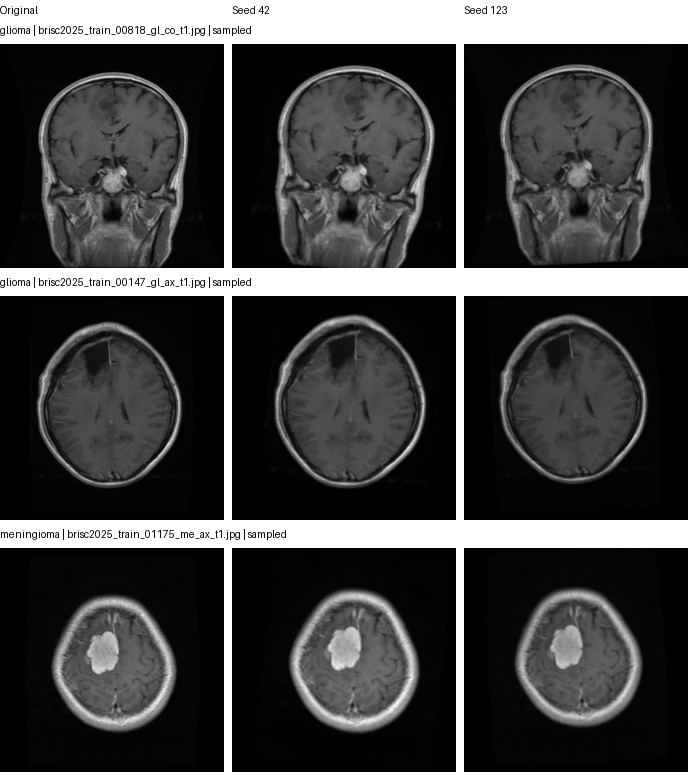

Panel 2


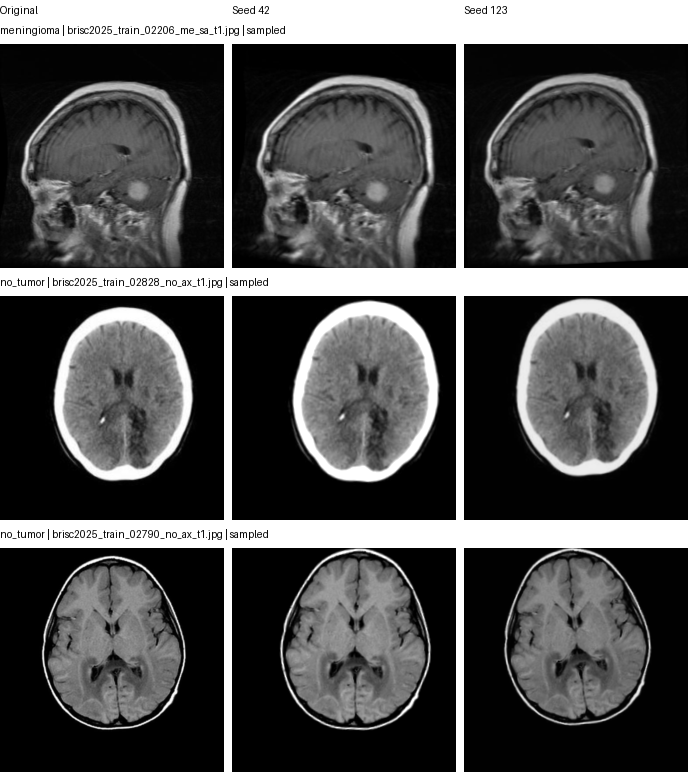

Panel 3


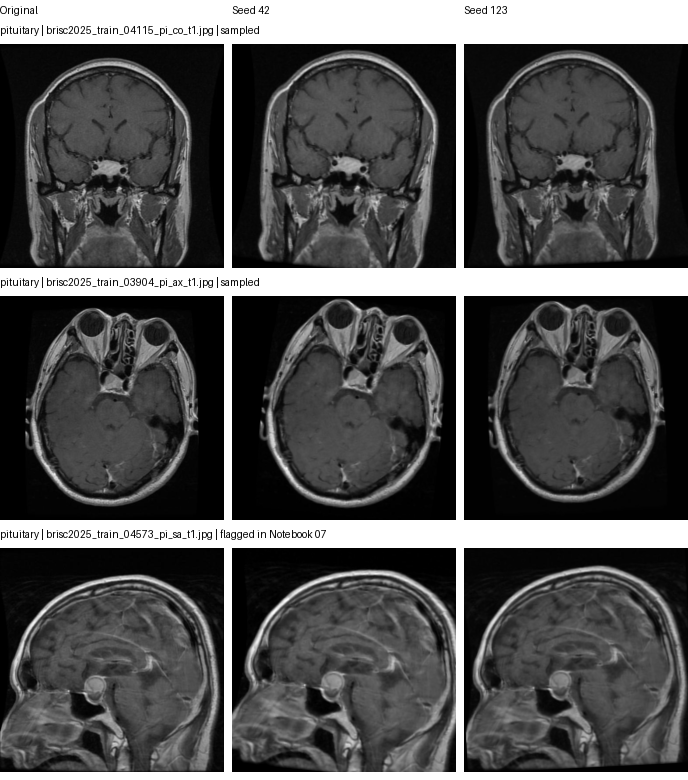

In [4]:
from IPython.display import display
from PIL import Image, ImageDraw
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode
from torchvision.transforms.functional import pil_to_tensor, to_pil_image

dataset_root = project_root / "data" / "raw" / "brisc2025"
image_size = preprocessing_config["classification"]["default_input_size"]
assert image_size == 224

def load_canonical_mri(path):
    with Image.open(path) as image:
        gray = image.convert("L")
        resized = gray.resize(
            (image_size, image_size),
            resample=Image.Resampling.BILINEAR,
        )
    single_channel = pil_to_tensor(resized).to(torch.float32) / 255.0
    return single_channel.repeat(3, 1, 1)


train_augmentation = T.Compose([
    T.RandomAffine(
        degrees=tuple(aug_policy["rotation_degrees"]),
        translate=(
            aug_policy["translation_fraction"]["horizontal"],
            aug_policy["translation_fraction"]["vertical"],
        ),
        scale=tuple(aug_policy["scale_range"]),
        interpolation=InterpolationMode.BILINEAR,
        fill=0,
    ),
    T.ColorJitter(
        brightness=tuple(aug_policy["brightness_factor_range"]),
        contrast=tuple(aug_policy["contrast_factor_range"]),
    ),
])


def preview_draw(original, seed):
    # Restore the CPU random state after each preview.
    with torch.random.fork_rng(devices=[]):
        torch.default_generator.manual_seed(seed)
        return train_augmentation(original)


gap = 8
header = 24
row_height = image_size + 28
width = 3 * image_size + 2 * gap

for start in range(0, len(review_cases), 3):
    group = review_cases[start:start + 3]
    panel = Image.new("RGB", (width, header + len(group) * row_height), "white")
    draw = ImageDraw.Draw(panel)

    for col, title in enumerate(("Original", "Seed 42", "Seed 123")):
        draw.text((col * (image_size + gap), 4), title, fill="black")

    for index, (reason, row) in enumerate(group):
        original = load_canonical_mri(dataset_root / row["relative_path"])
        variants = (original, preview_draw(original, 42), preview_draw(original, 123))

        y = header + index * row_height
        caption = f"{row['tumor_label']} | {row['filename']} | {reason}"
        draw.text((0, y), caption, fill="black")

        for col, tensor in enumerate(variants):
            assert tensor.shape == (3, image_size, image_size)
            assert torch.isfinite(tensor).all().item()
            tile = to_pil_image(tensor[0])
            panel.paste(tile, (col * (image_size + gap), y + 20))

    print(f"Panel {start // 3 + 1}")
    display(panel)

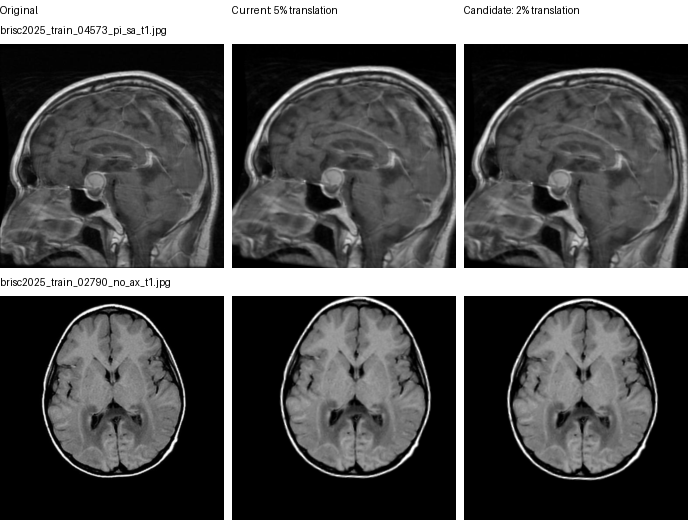

In [5]:
candidate_affine = T.RandomAffine(
    degrees=tuple(aug_policy["rotation_degrees"]),
    translate=(0.02, 0.02),
    scale=tuple(aug_policy["scale_range"]),
    interpolation=InterpolationMode.BILINEAR,
    fill=0,
)

candidate_augmentation = T.Compose([
    candidate_affine,
    train_augmentation.transforms[1],  # Same brightness and contrast settings
])

comparison_files = (
    "brisc2025_train_04573_pi_sa_t1.jpg",
    "brisc2025_train_02790_no_ax_t1.jpg",
)
review_by_name = {row["filename"]: row for _, row in review_cases}

width = 3 * image_size + 2 * gap
comparison = Image.new("RGB", (width, 24 + 2 * (image_size + 28)), "white")
draw = ImageDraw.Draw(comparison)

for col, title in enumerate(("Original", "Current: 5% translation", "Candidate: 2% translation")):
    draw.text((col * (image_size + gap), 4), title, fill="black")

for index, filename in enumerate(comparison_files):
    row = review_by_name[filename]
    original = load_canonical_mri(dataset_root / row["relative_path"])

    # Reset the seed for each policy so the comparison uses paired draws.
    variants = [original]
    for transform in (train_augmentation, candidate_augmentation):
        with torch.random.fork_rng(devices=[]):
            torch.default_generator.manual_seed(42)
            variants.append(transform(original))

    y = 24 + index * (image_size + 28)
    draw.text((0, y), filename, fill="black")

    for col, tensor in enumerate(variants):
        comparison.paste(
            to_pil_image(tensor[0]),
            (col * (image_size + gap), y + 20),
        )

display(comparison)

### Training augmentation review

We reviewed eight class-balanced sampled training images and one previously
flagged pituitary image using seeds 42 and 123. We then compared 5% and 2%
maximum translation per axis on two selected edge-sensitive images using
seed 42, with the other augmentation settings held fixed.

At 2%, the no_tumor image 02790 showed a small visible upper margin. The
pituitary image 04573 remained tightly framed on the right. We propose 2%
maximum translation per axis for all three classifiers, pending independent
review. These selected examples do not estimate the frequency of clipping
across the dataset. The frozen Notebook 05 configuration records the original
5% setting.

In [6]:
protocol_draft = {
    "status": "draft_for_review",
    "model_ids": [
        "mobilenetv4_conv_small.e2400_r224_in1k",
        "convnextv2_atto.fcmae_ft_in1k",
        "repvit_m0_9.dist_450e_in1k",
    ],
    "initialization": "selected pretrained checkpoint with a new four-class head",
    "fine_tuning": "all layers trainable from epoch 1",
    "class_to_index": class_to_index.copy(),
    "batch_size": 8,
    "precision": "float32",
    "optimizer": "AdamW",
    "learning_rate": 0.0001,
    "weight_decay": 0.01,
    "lr_schedule": "constant",
    "loss": "unweighted cross-entropy",
    "epochs_per_run": 15,
    "seeds": [42, 123, 2026],
    "augmentation": {
        "base_config_sha256": config_hash,
        "proposed_translation_fraction_per_axis": 0.02,
        "translation_status": "pending independent review",
    },
    "validation": {
        "frequency": "after every epoch",
        "selection_metric": "macro-F1 across all four classes",
        "tie_break": "earliest epoch with the highest unrounded macro-F1",
    },
    "reporting": "report every seed and the mean and standard deviation per model",
    "official_test": "evaluate after protocol and checkpoint choices are fixed",
}

run_count = len(protocol_draft["model_ids"]) * len(protocol_draft["seeds"])

print("Protocol status:", protocol_draft["status"])
print("Planned runs:", run_count)
print("Epochs per run:", protocol_draft["epochs_per_run"])
print("Total planned training epochs:", run_count * protocol_draft["epochs_per_run"])
print("Checkpoint selection:", protocol_draft["validation"]["selection_metric"])
print("Tie-break:", protocol_draft["validation"]["tie_break"])

Protocol status: draft_for_review
Planned runs: 9
Epochs per run: 15
Total planned training epochs: 135
Checkpoint selection: macro-F1 across all four classes
Tie-break: earliest epoch with the highest unrounded macro-F1


In [7]:
from math import isclose

def four_class_f1(targets, predictions):
    """Return per-class F1 and macro-F1 from a full set of class indices."""
    targets = torch.as_tensor(targets, dtype=torch.long, device="cpu")
    predictions = torch.as_tensor(predictions, dtype=torch.long, device="cpu")
    n_classes = len(class_names)

    if targets.ndim != 1 or targets.shape != predictions.shape or targets.numel() == 0:
        raise ValueError("Expected two nonempty, equally sized 1D sequences.")

    for values in (targets, predictions):
        if ((values < 0) | (values >= n_classes)).any().item():
            raise ValueError("Found a class index outside the class map.")

    # Rows are true classes. Columns are predicted classes.
    counts = torch.bincount(targets * n_classes + predictions,
                            minlength=n_classes ** 2)
    matrix = counts.reshape(n_classes, n_classes)
    per_class = {}

    for index, name in enumerate(class_names):
        true_positives = matrix[index, index].item()
        actual_count = matrix[index, :].sum().item()
        predicted_count = matrix[:, index].sum().item()
        denominator = actual_count + predicted_count
        per_class[name] = 2 * true_positives / denominator if denominator else 0.0

    return per_class, sum(per_class.values()) / n_classes


toy_targets      = [0, 0, 1, 1, 2, 3]
toy_predictions  = [0, 0, 1, 0, 2, 2]
expected_f1 = {"glioma": 4/5, "meningioma": 2/3, "no_tumor": 2/3, "pituitary": 0.0}

per_class, macro_f1 = four_class_f1(toy_targets, toy_predictions)

for name, expected in expected_f1.items():
    assert isclose(per_class[name], expected, abs_tol=1e-12), name
    print(f"{name}: {per_class[name]:.6f}")

assert isclose(macro_f1, 8/15, abs_tol=1e-12)
print(f"Macro-F1: {macro_f1:.6f}")
print("PASS | all four class scores and macro-F1 match the hand calculation")

glioma: 0.800000
meningioma: 0.666667
no_tumor: 0.666667
pituitary: 0.000000
Macro-F1: 0.533333
PASS | all four class scores and macro-F1 match the hand calculation


In [8]:
from math import isfinite

def is_better_checkpoint(current_score, best_score):
    """Return True when the current epoch should become the new best."""
    if not isfinite(current_score) or not 0.0 <= current_score <= 1.0:
        raise ValueError(f"Invalid validation macro-F1: {current_score}")
    return best_score is None or current_score > best_score


# Epoch 3 ties epoch 2 exactly.
# Epoch 4 improves slightly, but both scores display as 0.700000.
# Epoch 5 ties epoch 4 exactly.
example_scores = [0.62, 0.70, 0.70, 0.7000004, 0.7000004]

best_score = None
best_epoch = None
selected_epochs = []

for epoch, score in enumerate(example_scores, start=1):
    if is_better_checkpoint(score, best_score):
        best_score = score
        best_epoch = epoch

    selected_epochs.append(best_epoch)
    print(f"Epoch {epoch} | score={score:.7f} | best epoch so far={best_epoch}")

assert selected_epochs == [1, 2, 2, 4, 4]
print("PASS | exact ties keep the earlier epoch and unrounded improvements count")

Epoch 1 | score=0.6200000 | best epoch so far=1
Epoch 2 | score=0.7000000 | best epoch so far=2
Epoch 3 | score=0.7000000 | best epoch so far=2
Epoch 4 | score=0.7000004 | best epoch so far=4
Epoch 5 | score=0.7000004 | best epoch so far=4
PASS | exact ties keep the earlier epoch and unrounded improvements count


In [9]:
from tempfile import TemporaryDirectory

with TemporaryDirectory() as temp_dir, torch.random.fork_rng(devices=[]):
    checkpoint_path = Path(temp_dir) / "best.pt"
    toy_model = torch.nn.Linear(1, 1, bias=False)
    best_toy_score = None

    for epoch, score in enumerate(example_scores, start=1):
        # Use the epoch number as a recognizable weight.
        with torch.no_grad():
            toy_model.weight.fill_(float(epoch))

        if is_better_checkpoint(score, best_toy_score):
            torch.save(
                {
                    "epoch": epoch,
                    "validation_macro_f1": score,
                    "model_state_dict": toy_model.state_dict(),
                },
                checkpoint_path,
            )
            best_toy_score = score

    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    restored_model = torch.nn.Linear(1, 1, bias=False)
    restored_model.load_state_dict(saved["model_state_dict"])

    final_weight = toy_model.weight.item()
    restored_weight = restored_model.weight.item()

    assert final_weight == 5.0
    assert saved["epoch"] == 4
    assert saved["validation_macro_f1"] == example_scores[3]
    assert restored_weight == 4.0

    print("Final in-memory weight:", final_weight)
    print("Saved best epoch:", saved["epoch"])
    print("Restored weight:", restored_weight)
    print("PASS | reloaded weights belong to the selected epoch")

Final in-memory weight: 5.0
Saved best epoch: 4
Restored weight: 4.0
PASS | reloaded weights belong to the selected epoch


In [10]:
from collections import Counter

def make_training_batches(n_images, batch_size, generator):
    order = torch.randperm(n_images, generator=generator).tolist()
    batches = [
        order[start:start + batch_size]
        for start in range(0, n_images, batch_size)
    ]

    # Move one image from the penultimate batch into the singleton batch.
    if len(batches) >= 2 and len(batches[-1]) == 1:
        batches[-1].insert(0, batches[-2].pop())

    return batches


batch_size = protocol_draft["batch_size"]
n_train = len(records["train"])
generator = torch.Generator().manual_seed(42)
epoch_batches = make_training_batches(n_train, batch_size, generator)

sizes = Counter(len(batch) for batch in epoch_batches)
all_indices = [index for batch in epoch_batches for index in batch]

# Sorting verifies that every manifest row occurs exactly once.
assert sorted(all_indices) == list(range(n_train))
assert sizes == {8: 485, 7: 1, 2: 1}

print("Training images covered:", len(all_indices))
print("Batches per epoch:", len(epoch_batches))
print("Batch counts by size:", dict(sorted(sizes.items())))
print("PASS | every training row appears once and the smallest batch has 2 images")

Training images covered: 3889
Batches per epoch: 487
Batch counts by size: {2: 1, 7: 1, 8: 485}
PASS | every training row appears once and the smallest batch has 2 images


In [11]:
def preview_two_epoch_orders(seed):
    # Create the generator once per run, outside the epoch loop.
    shuffle_generator = torch.Generator().manual_seed(seed)
    orders = []

    for _ in range(2):
        batches = make_training_batches(n_train, batch_size, shuffle_generator)
        order = [index for batch in batches for index in batch]

        assert sorted(order) == list(range(n_train))
        assert [len(batch) for batch in batches[-2:]] == [7, 2]
        orders.append(order)

    return orders


first_run = preview_two_epoch_orders(42)
repeat_run = preview_two_epoch_orders(42)

assert first_run[0] != first_run[1], "The shuffle repeated in epoch 2."
assert first_run == repeat_run, "Restarting with seed 42 changed the orders."

print("Epoch 1, first 8 row indices:", first_run[0][:8])
print("Epoch 2, first 8 row indices:", first_run[1][:8])
print("PASS | epoch order changes and both orders reproduce with seed 42")

Epoch 1, first 8 row indices: [3249, 996, 1152, 2663, 400, 1380, 867, 405]
Epoch 2, first 8 row indices: [1493, 1108, 3864, 831, 1172, 3097, 2017, 806]
PASS | epoch order changes and both orders reproduce with seed 42


In [12]:
def augment_training_image(image, run_seed, epoch, row_index, transform):
    # A stable seed for this specific image in this specific epoch and run.
    key = f"{run_seed}:{epoch}:{row_index}".encode("ascii")
    draw_seed = int.from_bytes(sha256(key).digest()[:8], byteorder="big")

    with torch.random.fork_rng(devices=[]):
        torch.default_generator.manual_seed(draw_seed)
        return transform(image)


row_index = first_run[0][0]
row = records["train"][row_index]
original = load_canonical_mri(dataset_root / row["relative_path"])

rng_before = torch.get_rng_state().clone()

epoch1_a = augment_training_image(original, 42, 1, row_index, candidate_augmentation)
epoch2 = augment_training_image(original, 42, 2, row_index, candidate_augmentation)
epoch1_b = augment_training_image(original, 42, 1, row_index, candidate_augmentation)

assert torch.equal(epoch1_a, epoch1_b), "Epoch 1 did not reproduce exactly."
assert torch.equal(torch.get_rng_state(), rng_before), "CPU random state changed."

print("Checked training file:", row["filename"])
print("Same image, seed, and epoch reproduce exactly:", torch.equal(epoch1_a, epoch1_b))
print("Epoch 2 differs for this image:", not torch.equal(epoch1_a, epoch2))
print("PASS | paired augmentation reproduces and preserves CPU random state")

Checked training file: brisc2025_train_03920_pi_ax_t1.jpg
Same image, seed, and epoch reproduce exactly: True
Epoch 2 differs for this image: True
PASS | paired augmentation reproduces and preserves CPU random state


In [13]:
from torch.utils.data import Dataset, DataLoader

# Shared checkpoint normalization verified for all three models in Notebook 07.
checkpoint_normalize = T.Normalize(
    mean=(0.485, 0.456, 0.406),
    std=(0.229, 0.224, 0.225),
)


class TrainingEpochDataset(Dataset):
    def __init__(self, rows, run_seed, epoch, transform):
        self.rows = rows
        self.run_seed = run_seed
        self.epoch = epoch
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        image = load_canonical_mri(dataset_root / row["relative_path"])
        image = augment_training_image(
            image, self.run_seed, self.epoch, index, self.transform
        )
        image = checkpoint_normalize(image)
        label = class_to_index[row["tumor_label"]]
        return image, label, index


preview_dataset = TrainingEpochDataset(
    records["train"], run_seed=42, epoch=1, transform=candidate_augmentation
)

# Reuse the exact epoch-1 batches verified in Cell 11.
preview_loader = DataLoader(
    preview_dataset,
    batch_sampler=epoch_batches,
    num_workers=0,
    generator=torch.Generator().manual_seed(42),
)

images, labels, indices = next(iter(preview_loader))
expected_indices = epoch_batches[0]
expected_labels = [
    class_to_index[records["train"][i]["tumor_label"]] for i in expected_indices
]

assert indices.tolist() == expected_indices
assert labels.tolist() == expected_labels
assert images.shape == (8, 3, 224, 224)
assert images.dtype == torch.float32
assert torch.isfinite(images).all().item()

# Independent of the loader: use the augmented image saved by Cell 13.
assert indices[0].item() == row_index
torch.testing.assert_close(
    images[0], checkpoint_normalize(epoch1_a), rtol=0, atol=0
)

print("Batch shape:", tuple(images.shape))
print("Manifest row indices:", indices.tolist())
print("Class indices:", labels.tolist())
print("PASS | training loader matches the verified order, labels, and first image")

Batch shape: (8, 3, 224, 224)
Manifest row indices: [3249, 996, 1152, 2663, 400, 1380, 867, 405]
Class indices: [3, 0, 0, 1, 0, 3, 3, 2]
PASS | training loader matches the verified order, labels, and first image


In [14]:
class ValidationDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        image = load_canonical_mri(dataset_root / row["relative_path"])
        image = checkpoint_normalize(image)
        return image, class_to_index[row["tumor_label"]], index


validation_rows = records["validation"]
validation_loader = DataLoader(
    ValidationDataset(validation_rows),
    batch_size=protocol_draft["batch_size"],
    shuffle=False,
    drop_last=False,
    num_workers=0,
    generator=torch.Generator().manual_seed(42),
)

seen_indices = []
seen_labels = []
batch_sizes = []

for val_images, val_labels, val_indices in validation_loader:
    count = len(val_indices)
    assert val_images.shape == (count, 3, 224, 224)
    assert val_images.dtype == torch.float32
    assert torch.isfinite(val_images).all().item(), (
        f"Non-finite validation input in rows {val_indices.tolist()}"
    )

    seen_indices.extend(val_indices.tolist())
    seen_labels.extend(val_labels.tolist())
    batch_sizes.append(count)

expected_labels = [class_to_index[row["tumor_label"]] for row in validation_rows]

assert seen_indices == list(range(len(validation_rows)))
assert seen_labels == expected_labels
assert batch_sizes == [8] * 121 + [5]

print("Validation images checked:", len(seen_indices))
print("Validation batches:", len(batch_sizes))
print("Final batch size:", batch_sizes[-1])
print("PASS | all validation rows loaded once in order with matching labels")

Validation images checked: 973
Validation batches: 122
Final batch size: 5
PASS | all validation rows loaded once in order with matching labels


In [15]:
import torch.nn.functional as F
from torch.utils.data import TensorDataset


@torch.inference_mode()
def evaluate_classifier(model, loader, device):
    model.eval()
    loss_sum = 0.0
    targets = []
    predictions = []
    row_indices = []

    for inputs, labels, indices in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        logits = model(inputs)

        assert logits.shape == (len(labels), len(class_names))
        assert torch.isfinite(logits).all().item(), "Non-finite validation scores"

        # Sum individual losses so every scan has equal weight.
        loss_sum += F.cross_entropy(logits, labels, reduction="sum").item()
        targets.extend(labels.cpu().tolist())
        predictions.extend(logits.argmax(dim=1).cpu().tolist())
        row_indices.extend(indices.tolist())

    # The validation loader is expected to preserve manifest order.
    assert row_indices == list(range(len(loader.dataset)))
    per_class, macro_f1 = four_class_f1(targets, predictions)
    correct = sum(pred == true for pred, true in zip(predictions, targets))

    return {
        "count": len(targets),
        "loss": loss_sum / len(targets),
        "accuracy": correct / len(targets),
        "per_class_f1": per_class,
        "macro_f1": macro_f1,
    }


# Fixed scores reproduce the six predictions from the hand calculation.
known_targets = torch.tensor([0, 0, 1, 1, 2, 3])
known_predictions = torch.tensor([0, 0, 1, 0, 2, 2])
known_logits = 3.0 * F.one_hot(known_predictions, num_classes=4).float()

check_dataset = TensorDataset(known_logits, known_targets, torch.arange(6))
check_loader = DataLoader(check_dataset, batch_size=4, shuffle=False)

# Identity passes the fixed scores through unchanged.
result = evaluate_classifier(torch.nn.Identity(), check_loader, "cpu")
reference_loss = F.cross_entropy(known_logits, known_targets).item()

assert result["count"] == 6
assert isclose(result["accuracy"], 4 / 6)
assert isclose(result["macro_f1"], 8 / 15)
assert isclose(result["loss"], reference_loss, abs_tol=1e-6)

print("Examples evaluated:", result["count"])
print(f"Accuracy: {result['accuracy']:.6f}")
print(f"Macro-F1: {result['macro_f1']:.6f}")
print("PASS | uneven-batch evaluation matches the full-set calculation")

Examples evaluated: 6
Accuracy: 0.666667
Macro-F1: 0.533333
PASS | uneven-batch evaluation matches the full-set calculation


In [16]:
def check_full_validation_pass():
    device = torch.device("cuda:0")
    model_id = "mobilenetv4_conv_small.e2400_r224_in1k"

    with torch.random.fork_rng(devices=[0]):
        torch.manual_seed(42)
        model = timm.create_model(
            model_id, pretrained=False, num_classes=len(class_names)
        ).to(device)

        result = evaluate_classifier(model, validation_loader, device)

    assert result["count"] == len(validation_rows) == 973
    assert isfinite(result["loss"]) and result["loss"] >= 0
    assert 0 <= result["accuracy"] <= 1
    assert 0 <= result["macro_f1"] <= 1
    assert set(result["per_class_f1"]) == set(class_names)
    assert all(0 <= value <= 1 for value in result["per_class_f1"].values())

    print("Model:", model_id)
    print("Validation scans evaluated:", result["count"])
    print("Per-class F1 entries:", len(result["per_class_f1"]))
    print("PASS | full GPU validation completed in manifest order")


check_full_validation_pass()

Model: mobilenetv4_conv_small.e2400_r224_in1k
Validation scans evaluated: 973
Per-class F1 entries: 4
PASS | full GPU validation completed in manifest order


In [17]:
checked = 0
observed_batch_sizes = []

for batch_number, (batch_images, batch_labels, batch_indices) in enumerate(preview_loader):
    indices = batch_indices.tolist()
    count = len(indices)

    assert indices == epoch_batches[batch_number], (
        f"Unexpected row order in batch {batch_number + 1}"
    )
    assert batch_images.shape == (count, 3, 224, 224)
    assert batch_images.dtype == torch.float32
    assert torch.isfinite(batch_images).all().item(), (
        f"Non-finite training tensor in batch {batch_number + 1}, rows {indices}"
    )

    expected = [
        class_to_index[records["train"][i]["tumor_label"]] for i in indices
    ]
    assert batch_labels.tolist() == expected, (
        f"Label mismatch in batch {batch_number + 1}"
    )

    checked += count
    observed_batch_sizes.append(count)

assert checked == len(records["train"]) == 3889
assert observed_batch_sizes == [8] * 485 + [7, 2]

print("Training scans loaded and augmented:", checked)
print("Training batches checked:", len(observed_batch_sizes))
print("Final two batch sizes:", observed_batch_sizes[-2:])
print("PASS | full training loader matches the verified epoch order and labels")

Training scans loaded and augmented: 3889
Training batches checked: 487
Final two batch sizes: [7, 2]
PASS | full training loader matches the verified epoch order and labels


In [18]:
from copy import deepcopy

# Preserve the Cell 7 draft and make a revised copy for review.
reviewed_draft = deepcopy(protocol_draft)

reviewed_draft["training_loader"] = {
    "num_workers": 0,
    "shuffle": "torch.randperm using one CPU generator per run, seeded once",
    "final_batch_rule": "if the last batch has one row, move one row from the preceding batch",
    "batches_per_epoch": len(observed_batch_sizes),
    "final_two_batch_sizes": observed_batch_sizes[-2:],
}

reviewed_draft["augmentation"]["seed_rule"] = (
    "Use the first 8 SHA-256 digest bytes of UTF-8 'run_seed:epoch:row_index' "
    "as an unsigned big-endian integer. Epoch numbering starts at 1. "
    "Row indices are zero-based positions in the frozen training manifest."
)

reviewed_draft["validation"].update({
    "rows_per_epoch": len(validation_rows),
    "order": "frozen validation manifest order",
    "loss_aggregation": "sum individual cross-entropy losses and divide by scan count",
    "f1_aggregation": "compute per-class F1 from all predictions, then average the four scores",
})

# Budget assumes one optimizer update per training batch.
steps_per_run = len(observed_batch_sizes) * reviewed_draft["epochs_per_run"]
planned_runs = len(reviewed_draft["model_ids"]) * len(reviewed_draft["seeds"])

print("Protocol status:", reviewed_draft["status"])
print("Optimizer updates per 15-epoch run:", steps_per_run)
print("Optimizer updates across all proposed runs:", steps_per_run * planned_runs)
print("Translation decision:", reviewed_draft["augmentation"]["translation_status"])

Protocol status: draft_for_review
Optimizer updates per 15-epoch run: 7305
Optimizer updates across all proposed runs: 65745
Translation decision: pending independent review


In [19]:
from timm.models import get_pretrained_cfg

checkpoint_registry = {}

for model_id in reviewed_draft["model_ids"]:
    cfg = get_pretrained_cfg(model_id)
    assert cfg is not None, f"No pretrained configuration found for {model_id}"

    expected_repo = f"timm/{model_id}"
    assert cfg.hf_hub_id == expected_repo, (
        f"{model_id}: expected {expected_repo}, found {cfg.hf_hub_id}"
    )
    assert cfg.num_classes == 1000, (
        f"{model_id}: unexpected source classifier size {cfg.num_classes}"
    )
    assert tuple(cfg.input_size) == (3, 224, 224)
    assert tuple(cfg.mean) == (0.485, 0.456, 0.406)
    assert tuple(cfg.std) == (0.229, 0.224, 0.225)

    checkpoint_registry[model_id] = {
        "repository": cfg.hf_hub_id,
        "source_classes": cfg.num_classes,
        "input_size": tuple(cfg.input_size),
    }

    print(f"{model_id} | {cfg.hf_hub_id} | source classes={cfg.num_classes}")

print("PASS | all three checkpoint identities and input settings match the draft")

mobilenetv4_conv_small.e2400_r224_in1k | timm/mobilenetv4_conv_small.e2400_r224_in1k | source classes=1000
convnextv2_atto.fcmae_ft_in1k | timm/convnextv2_atto.fcmae_ft_in1k | source classes=1000
repvit_m0_9.dist_450e_in1k | timm/repvit_m0_9.dist_450e_in1k | source classes=1000
PASS | all three checkpoint identities and input settings match the draft


In [20]:
from huggingface_hub import HfApi

api = HfApi()
checkpoint_pins = {}

for model_id, entry in checkpoint_registry.items():
    repo_id = entry["repository"]
    info = api.model_info(repo_id=repo_id, token=False)

    assert info.sha, f"No commit identifier returned for {repo_id}"
    filenames = {file.rfilename for file in info.siblings}
    weight_file = "model.safetensors"

    if weight_file not in filenames:
        raise ValueError(
            f"{repo_id} has no file named {weight_file}. "
            f"Available files: {sorted(filenames)}"
        )

    checkpoint_pins[model_id] = {
        "repository": repo_id,
        "revision": info.sha,
        "filename": weight_file,
    }

    print(f"{model_id} | {info.sha} | {weight_file}")

assert set(checkpoint_pins) == set(reviewed_draft["model_ids"])
reviewed_draft["pretrained_checkpoints"] = checkpoint_pins.copy()
print("PASS | exact revisions and weight filenames recorded for all three models")

mobilenetv4_conv_small.e2400_r224_in1k | 331fb803779522b685cf942e15f914fb6741c1eb | model.safetensors
convnextv2_atto.fcmae_ft_in1k | 2de59190576d00653aabde4bcd4af7525a93ad1b | model.safetensors
repvit_m0_9.dist_450e_in1k | c073717dd84b5af671dd51b187b99ac55b2af4f0 | model.safetensors
PASS | exact revisions and weight filenames recorded for all three models


In [21]:
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

study_revisions = {
    "mobilenetv4_conv_small.e2400_r224_in1k":
        "331fb803779522b685cf942e15f914fb6741c1eb",
    "convnextv2_atto.fcmae_ft_in1k":
        "2de59190576d00653aabde4bcd4af7525a93ad1b",
    "repvit_m0_9.dist_450e_in1k":
        "c073717dd84b5af671dd51b187b99ac55b2af4f0",
}

assert set(study_revisions) == set(reviewed_draft["model_ids"])
verified_weights = {}

for model_id, revision in study_revisions.items():
    repo_id = checkpoint_registry[model_id]["repository"]
    print(f"Checking {model_id} ...", flush=True)

    weight_path = Path(hf_hub_download(
        repo_id=repo_id,
        filename="model.safetensors",
        revision=revision,
        token=False,
    ))
    file_hash = sha256(weight_path.read_bytes()).hexdigest()

    # Build the source architecture, then explicitly load the pinned file.
    source_model = timm.create_model(model_id, pretrained=False, num_classes=1000)
    state_dict = load_file(str(weight_path), device="cpu")
    source_model.load_state_dict(state_dict, strict=True)

    source_model.eval()
    with torch.inference_mode():
        scores = source_model(torch.zeros(1, 3, 224, 224))

    assert scores.shape == (1, 1000), f"Unexpected output shape: {scores.shape}"
    assert torch.isfinite(scores).all().item(), "Non-finite source-model output"

    verified_weights[model_id] = {
        "repository": repo_id,
        "revision": revision,
        "filename": weight_path.name,
        "sha256": file_hash,
    }

    print(f"PASS | source output={tuple(scores.shape)} | SHA-256={file_hash}")
    del source_model, state_dict, scores

reviewed_draft["pretrained_checkpoints"] = verified_weights.copy()

Checking mobilenetv4_conv_small.e2400_r224_in1k ...


C:\Users\HP\miniconda3\envs\brainxai-train\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\HP\miniconda3\envs\brainxai-train\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-sy

PASS | source output=(1, 1000) | SHA-256=7a7102ec18f62bbfb555b6fe829bbb5af749516b84174926c29ffdfdfc03aec4
Checking convnextv2_atto.fcmae_ft_in1k ...
PASS | source output=(1, 1000) | SHA-256=6389c2f5a427b01a922e66e6d352c707424cccb62390c6936bc612e3d10b7ebb
Checking repvit_m0_9.dist_450e_in1k ...


C:\Users\HP\miniconda3\envs\brainxai-train\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\models--timm--convnextv2_atto.fcmae_ft_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\HP\miniconda3\envs\brainxai-train\Lib\site-packages\huggingface_hub\file_download.py:

PASS | source output=(1, 1000) | SHA-256=c2dd32622df856ea7a68d6b241c1623f0e6fbec8acde381a3519cb5a5463e9cf


In [22]:
expected_parameters = {
    "mobilenetv4_conv_small.e2400_r224_in1k": 2_498_148,
    "convnextv2_atto.fcmae_ft_in1k": 3_388_684,
    "repvit_m0_9.dist_450e_in1k": 4_722_408,
}


def build_brisc_model(model_id, seed):
    pin = verified_weights[model_id]
    path = Path(hf_hub_download(
        repo_id=pin["repository"],
        revision=pin["revision"],
        filename=pin["filename"],
        local_files_only=True,
    ))
    assert sha256(path.read_bytes()).hexdigest() == pin["sha256"], model_id
    source = load_file(str(path), device="cpu")

    with torch.random.fork_rng(devices=[]):
        torch.default_generator.manual_seed(seed)
        model = timm.create_model(model_id, pretrained=False, num_classes=4)

    target = model.state_dict()
    assert source.keys() == target.keys(), f"{model_id}: unexpected tensor names"

    fresh_names = []
    for name, tensor in source.items():
        if tensor.shape == target[name].shape:
            target[name] = tensor
            continue

        # Allow only changes from 1,000 output rows to four output rows.
        old_shape = tuple(tensor.shape)
        new_shape = tuple(target[name].shape)
        assert old_shape[:1] == (1000,) and new_shape == (4,) + old_shape[1:], (
            f"{model_id}: unexpected shape change for {name}: "
            f"{old_shape} -> {new_shape}"
        )
        fresh_names.append(name)

    assert fresh_names, f"{model_id}: no four-class output tensors identified"
    model.load_state_dict(target, strict=True)
    return model, fresh_names


for model_id in reviewed_draft["model_ids"]:
    model, fresh_names = build_brisc_model(model_id, seed=42)
    parameter_count = sum(p.numel() for p in model.parameters())
    assert parameter_count == expected_parameters[model_id]

    model.eval()
    with torch.inference_mode():
        scores = model(torch.zeros(1, 3, 224, 224))

    assert scores.shape == (1, 4) and torch.isfinite(scores).all().item()
    print(f"PASS | {model_id} | {parameter_count:,} parameters")
    print("Fresh four-class tensors:", ", ".join(fresh_names))
    del model, scores

PASS | mobilenetv4_conv_small.e2400_r224_in1k | 2,498,148 parameters
Fresh four-class tensors: classifier.bias, classifier.weight
PASS | convnextv2_atto.fcmae_ft_in1k | 3,388,684 parameters
Fresh four-class tensors: head.fc.bias, head.fc.weight
PASS | repvit_m0_9.dist_450e_in1k | 4,722,408 parameters
Fresh four-class tensors: head.head.l.bias, head.head.l.weight, head.head_dist.l.bias, head.head_dist.l.weight


In [23]:
def check_repvit_heads():
    model_id = "repvit_m0_9.dist_450e_in1k"
    model, _ = build_brisc_model(model_id, seed=42)
    head_outputs = {}

    def capture(name):
        def hook(module, inputs, output):
            head_outputs[name] = output.detach().clone()
        return hook

    main_hook = model.head.head.register_forward_hook(capture("main"))
    dist_hook = model.head.head_dist.register_forward_hook(capture("distillation"))

    generator = torch.Generator().manual_seed(42)
    inputs = torch.randn(2, 3, 224, 224, generator=generator)

    try:
        for mode in ("eval", "train"):
            model.train(mode == "train")
            head_outputs.clear()

            with torch.no_grad():
                scores = model(inputs)

            assert isinstance(scores, torch.Tensor), (
                f"{mode}: expected one score tensor, got {type(scores).__name__}"
            )
            assert set(head_outputs) == {"main", "distillation"}
            assert scores.shape == (2, 4)
            assert torch.isfinite(scores).all().item()

            expected = (head_outputs["main"] + head_outputs["distillation"]) / 2
            torch.testing.assert_close(scores, expected, rtol=1e-5, atol=1e-6)
            print(f"PASS | {mode} | output=(2, 4) | equals mean of both heads")
    finally:
        main_hook.remove()
        dist_hook.remove()


check_repvit_heads()

PASS | eval | output=(2, 4) | equals mean of both heads
PASS | train | output=(2, 4) | equals mean of both heads


In [24]:
from copy import deepcopy
import json

protocol_snapshot = deepcopy(reviewed_draft)

# Record implementation details used in the pilot and preflight.
protocol_snapshot["optimizer_options"] = {"foreach": False}
protocol_snapshot["environment"] = {
    "python": sys.version.split()[0],
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "timm": str(timm.__version__),
    "gpu": torch.cuda.get_device_name(0),
}
protocol_snapshot["development_manifest_sha256"] = dict(expected_hashes)
protocol_snapshot["repvit_output"] = {
    "implementation": "timm 1.0.31",
    "verified_modes": ["train", "eval"],
    "logits": "arithmetic mean of main and distillation head logits",
    "loss_input": "model output directly",
}

assert protocol_snapshot["status"] == "draft_for_review"
assert set(protocol_snapshot["pretrained_checkpoints"]) == set(protocol_snapshot["model_ids"])
assert all(
    "sha256" in entry and "revision" in entry
    for entry in protocol_snapshot["pretrained_checkpoints"].values()
)

config_dir = project_root / "configs"
config_dir.mkdir(exist_ok=True)
draft_path = config_dir / "brisc_training_protocol_draft_v1.json"

# An identical rerun is fine. Preserve an existing draft if its contents differ.
if draft_path.exists():
    existing = json.loads(draft_path.read_text(encoding="utf-8"))
    if existing != protocol_snapshot:
        raise ValueError(f"A different draft already exists at {draft_path}")
else:
    with draft_path.open("x", encoding="utf-8") as file:
        json.dump(protocol_snapshot, file, indent=2, ensure_ascii=False)
        file.write("\n")

saved_draft = json.loads(draft_path.read_text(encoding="utf-8"))
assert saved_draft == protocol_snapshot

print("Draft file:", draft_path)
print("Status:", saved_draft["status"])
print("Pinned checkpoints:", len(saved_draft["pretrained_checkpoints"]))
print("Draft SHA-256:", sha256(draft_path.read_bytes()).hexdigest())
print("PASS | protocol draft saved and reloaded exactly")

Draft file: C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\configs\brisc_training_protocol_draft_v1.json
Status: draft_for_review
Pinned checkpoints: 3
Draft SHA-256: 60818f97e867d5983af420c92e0d948525ce798480bddd9935d6c00500992b9d
PASS | protocol draft saved and reloaded exactly


### Notebook 08 conclusion — training protocol and preflight

We verified all 3,889 training records and all 973 validation records through
their respective loaders. The training loader covered every row once in 487
batches, ending with batches of 7 and 2. Validation covered all 973 rows in
122 batches, including the final five images.

We checked macro-F1 against a hand calculation, verified loss aggregation
across unequal batch sizes, and confirmed that an exact validation-score tie
retains the earlier epoch. A save-and-reload test recovered the selected
epoch's weights. MobileNetV4 also completed a full GPU validation pass with
random weights to check the evaluation pipeline.

All three pinned pretrained checkpoints loaded successfully. Their four-class
models retained the compatible pretrained tensors and produced finite outputs.
For RepViT M0.9, the installed implementation averaged its two heads' logits
in both training and evaluation mode.

The shared protocol is saved as configs/brisc_training_protocol_draft_v1.json.
It proposes three seeds and 15 epochs per model. The 2% training translation
limit is pending independent review. Architecture confirmation, protocol
approval, and full-epoch runtime measurement remain open.

No model has been trained on BRISC, and the official test set has not been
used for model selection.